### Installation of Dependencies

In [1]:
!pip install tensorflow opencv-python matplotlib scikit-learn lime

### Import Libraries

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from lime import lime_image
from skimage.segmentation import mark_boundaries

c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Define Dataset Paths

In [3]:
BASE_PATH = "archive"

TRAIN_PATH = os.path.join(BASE_PATH, "Training")
TEST_PATH = os.path.join(BASE_PATH, "Testing")

CATEGORIES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = 224

In [4]:
print(os.getcwd())

d:\XAI_project


In [5]:
import os

print("Current Directory:", os.getcwd())
print("Archive exists:", os.path.exists("archive"))
print("Training exists:", os.path.exists("archive/Training"))
print("Testing exists:", os.path.exists("archive/testing"))

print("Training folders:", os.listdir("archive/Training"))
print("Testing folders:", os.listdir("archive/testing"))

Current Directory: d:\XAI_project
Archive exists: True
Training exists: True
Testing exists: True
Training folders: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing folders: ['glioma', 'meningioma', 'notumor', 'pituitary']


### Data Loading Function

In [6]:
def load_data(path):
    data = []
    labels = []

    for category in CATEGORIES:
        folder = os.path.join(path, category)
        class_num = CATEGORIES.index(category)

        for img in os.listdir(folder):
            try:
                img_path = os.path.join(folder, img)
                img_array = cv2.imread(img_path)
                img_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))

                data.append(img_array)
                labels.append(class_num)
            except:
                pass

    return np.array(data)/255.0, np.array(labels)

### Load Dataset

In [7]:
X_train, y_train = load_data(TRAIN_PATH)
X_test, y_test = load_data(TEST_PATH)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (5600, 224, 224, 3)
Test shape: (1600, 224, 224, 3)


### Build CNN + Attention Model

In [8]:
def attention_block(inputs):
    attention = layers.Conv2D(1, (1,1), activation='sigmoid')(inputs)
    return layers.multiply([inputs, attention])

def build_model():
    inputs = layers.Input(shape=(224, 224, 3))

    x = layers.Conv2D(32, (3,3), activation='relu')(inputs)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, (3,3), activation='relu')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, (3,3), activation='relu', name="last_conv")(x)

    # Attention
    x = attention_block(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)

    outputs = layers.Dense(len(CATEGORIES), activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model

model = build_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 222, 222,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 111, 111,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 109, 109,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 54, 54,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_conv (Conv2D)  │ (None, 52, 52,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 52, 52, 1) │        129 │ last_conv[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 52, 52,    │          0 │ last_conv[0][0],  │
│                     │ 128)              │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │        260 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 101,893 (398.02 KB)

 Trainable params: 101,893 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

### Compile Model

In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Data Generator (Memory Efficient)

In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 16   # reduce if still memory issue

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.1
)

train_generator = train_datagen.flow_from_directory(
    "archive/Training",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    "archive/Training",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    subset='validation'
)

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "archive/testing",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=False
)

Found 5040 images belonging to 4 classes.
Found 560 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


### Train model

In [11]:
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator
)

Epoch 1/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 92s 284ms/step - accuracy: 0.5296 - loss: 1.0380 - val_accuracy: 0.6821 - val_loss: 0.8447
Epoch 2/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 92s 291ms/step - accuracy: 0.6778 - loss: 0.8201 - val_accuracy: 0.6786 - val_loss: 0.7852
Epoch 3/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 86s 272ms/step - accuracy: 0.7038 - loss: 0.7346 - val_accuracy: 0.7054 - val_loss: 0.7105
Epoch 4/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 86s 273ms/step - accuracy: 0.7210 - loss: 0.6938 - val_accuracy: 0.6911 - val_loss: 0.6949
Epoch 5/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 110s 351ms/step - accuracy: 0.7375 - loss: 0.6541 - val_accuracy: 0.6893 - val_loss: 0.7051
Epoch 6/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 101s 319ms/step - accuracy: 0.7534 - loss: 0.6162 - val_accuracy: 0.7339 - val_loss: 0.6720
Epoch 7/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 84s 267ms/step - accuracy: 0.7631 - loss: 0.6013 - val_accuracy: 0.7786 - val_loss: 0.5661
Epoch 8/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 80s 253ms/step - accuracy: 0.7831 - loss:

In [12]:
pred = model.predict(X_test)

print("Raw Prediction:", pred[0])

50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 169ms/step
Raw Prediction: [1.1535127e-05 2.9458708e-01 6.9478214e-01 1.0619279e-02]


### Accuracy & Loss Plot

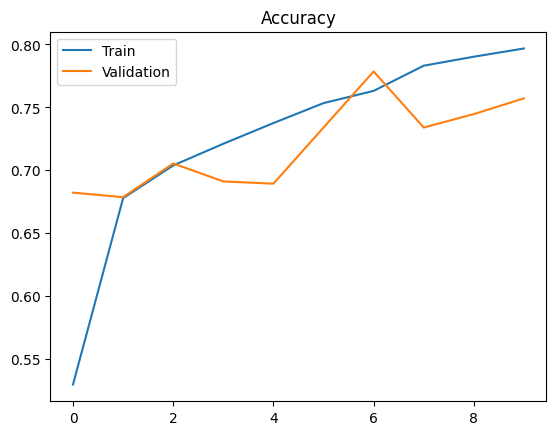

In [ ]:
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.legend()
plt.title("Accuracy")
plt.show()

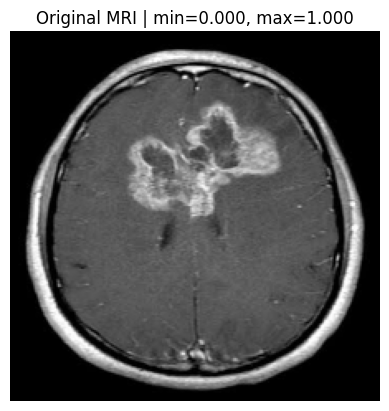

In [14]:

def normalize(img):
    if img.max() > 1:
        return img.astype('float32') / 255.0
    return img.astype('float32')

background = normalize(X_train[:10])
sample = normalize(X_test[:1])


import matplotlib.pyplot as plt

plt.imshow(sample[0])
plt.title(f"Original MRI | min={sample.min():.3f}, max={sample.max():.3f}")
plt.axis('off')
plt.show()

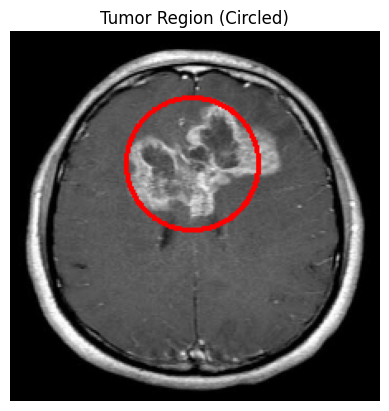

In [15]:
import cv2
import matplotlib.pyplot as plt

img = sample[0].copy()

# Convert to displayable format
img = (img * 255).astype('uint8')

# Draw circle (adjust coordinates if needed)
# (x, y, radius)
cv2.circle(img, (110, 80), 40, (255, 0, 0), 2)

plt.imshow(img)
plt.title("Tumor Region (Circled)")
plt.axis('off')
plt.show()

### Grad-CAM Function

In [16]:
def get_gradcam_heatmap(model, image):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer("last_conv").output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image)
        class_idx = np.argmax(predictions[0])
        loss = predictions[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = np.maximum(heatmap, 0) / np.max(heatmap)
    return heatmap

### Grad-CAM Visualization

c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


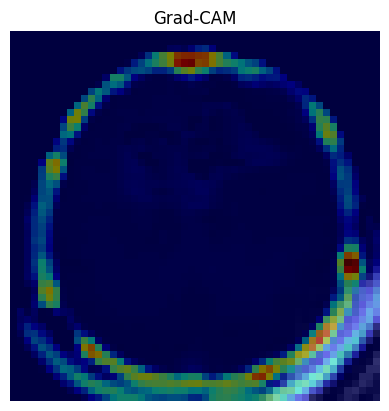

In [17]:
img_batch, label_batch = next(test_generator)

img = img_batch[0]

input_img = np.expand_dims(img, axis=0)

heatmap = get_gradcam_heatmap(model, input_img)

plt.imshow(img)
plt.imshow(heatmap, cmap='jet', alpha=0.5)
plt.title("Grad-CAM")
plt.axis('off')
plt.show()

### Attention Map Visualization

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


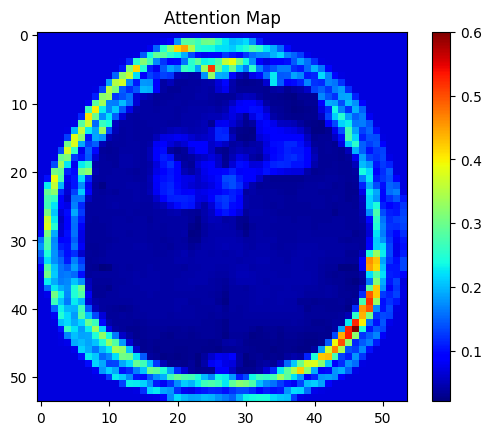

In [18]:
attention_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.get_layer(index=4).output  # attention layer output
)

attention_map = attention_model.predict(input_img)[0]

plt.imshow(np.mean(attention_map, axis=-1), cmap='jet')
plt.title("Attention Map")
plt.colorbar()
plt.show()

### LIME Explanation

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step


  1%|          | 10/1000 [00:00<00:20, 48.82it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


  2%|▏         | 20/1000 [00:00<00:14, 65.89it/s]

...

 98%|█████████▊| 980/1000 [00:12<00:00, 75.65it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


 99%|█████████▉| 990/1000 [00:12<00:00, 75.08it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


100%|██████████| 1000/1000 [00:13<00:00, 76.39it/s]


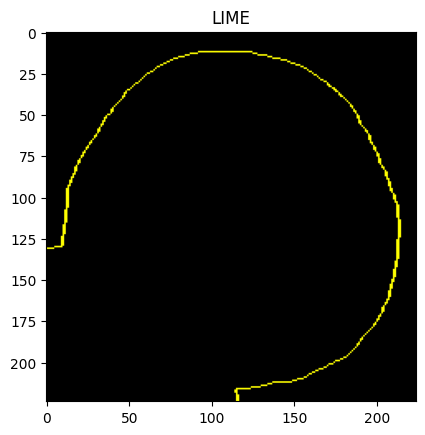

In [19]:
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    img.astype('double'),
    model.predict,
    top_labels=1,
    hide_color=0,
    num_samples=1000
)

temp, mask = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=True,
    num_features=5,
    hide_rest=False
)

plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME")
plt.show()

## Model Evaluation & Explainability Dashboard
### Trustworthy, Well-Explained Outputs
New sections:
1. **Memory-safe test-set evaluation** (uses generator, not X_test)
2. **Confusion matrix** with class labels
3. **Single-image prediction report** with confidence bar chart
4. **Grad-CAM** with trustworthiness metric
5. **Attention map** with entropy metric
6. **LIME** with superpixel weights
7. **Cross-method trustworthiness panel**


### Evaluation on Test Set (Memory-Safe)

In [22]:
# Uses the test GENERATOR — avoids loading all 1600 images into RAM
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

CATEGORIES = ["glioma", "meningioma", "notumor", "pituitary"]

test_generator.reset()
all_true, all_pred, all_prob = [], [], []

for step in range(len(test_generator)):
    X_b, y_b = next(test_generator)
    probs_b = model.predict(X_b, verbose=0)
    all_true.extend(y_b.astype(int))
    all_pred.extend(np.argmax(probs_b, axis=1))
    all_prob.extend(probs_b)

y_true = np.array(all_true)
y_pred_arr = np.array(all_pred)
y_prob = np.array(all_prob)

print(f"Overall Test Accuracy : {accuracy_score(y_true, y_pred_arr)*100:.2f}%\n")
print("Per-class Report:")
print(classification_report(y_true, y_pred_arr, target_names=CATEGORIES))


Overall Test Accuracy : 69.81%

Per-class Report:
              precision    recall  f1-score   support

      glioma       0.79      0.49      0.60       400
  meningioma       0.51      0.62      0.56       400
     notumor       0.73      0.94      0.82       400
   pituitary       0.84      0.74      0.79       400

    accuracy                           0.70      1600
   macro avg       0.72      0.70      0.69      1600
weighted avg       0.72      0.70      0.69      1600



### Confusion Matrix
Diagonal = correct predictions. Off-diagonal = misclassifications.
A trustworthy model keeps off-diagonal counts close to zero.

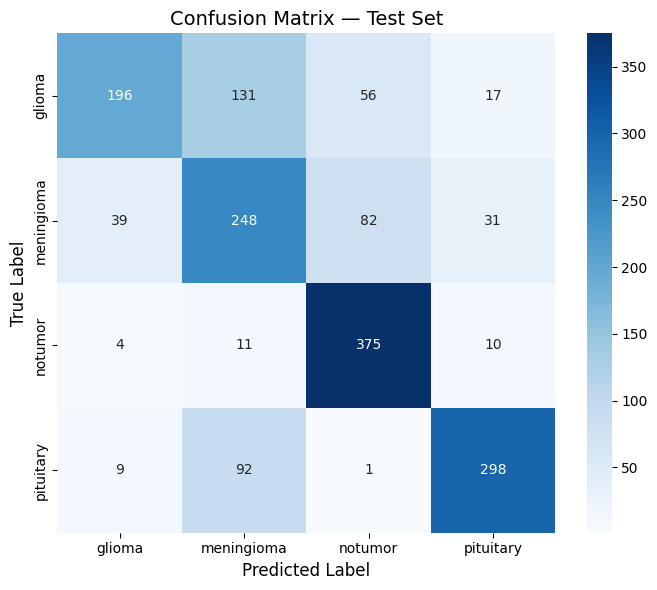


Per-class accuracy:
  glioma      : 49.0%
  meningioma  : 62.0%
  notumor     : 93.8%
  pituitary   : 74.5%


In [23]:
cm = confusion_matrix(y_true, y_pred_arr)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CATEGORIES, yticklabels=CATEGORIES, ax=ax)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_title("Confusion Matrix — Test Set", fontsize=14)
plt.tight_layout(); plt.show()

print("\nPer-class accuracy:")
for i, cls in enumerate(CATEGORIES):
    mask = y_true == i
    print(f"  {cls:<12}: {accuracy_score(y_true[mask], y_pred_arr[mask])*100:.1f}%")


### Single-Image Prediction Report
Shows the model's predicted class, confidence (softmax probability), and a bar chart.
> **Trust check:** High confidence on the correct class = reliable. Flat probabilities = uncertain model.


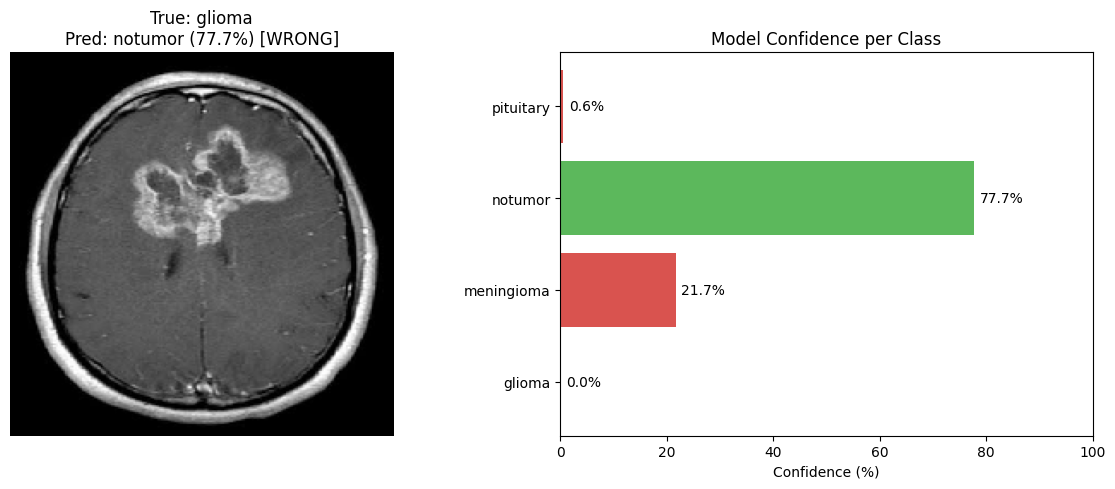

True label      : glioma
Predicted label : notumor
Confidence      : 77.74%
Outcome         : WRONG

Probability distribution:
  glioma      :   0.0%  
  meningioma  :  21.7%  ########
  notumor     :  77.7%  ###############################
  pituitary   :   0.6%  


In [25]:
test_generator.reset()
img_batch, label_batch = next(test_generator)
img = img_batch[0]
true_lbl = int(label_batch[0])
input_img = np.expand_dims(img, axis=0)

probs = model.predict(input_img, verbose=0)[0]
pred_lbl = int(np.argmax(probs))
confidence = float(probs[pred_lbl]) * 100
correct_str = "CORRECT" if pred_lbl == true_lbl else "WRONG"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(img)
axes[0].axis("off")
axes[0].set_title(
    f"True: {CATEGORIES[true_lbl]}\nPred: {CATEGORIES[pred_lbl]} ({confidence:.1f}%) [{correct_str}]",
    fontsize=12
)

colors = ["#d9534f" if i != pred_lbl else "#5cb85c" for i in range(4)]
bars = axes[1].barh(CATEGORIES, probs * 100, color=colors)
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Confidence (%)")
axes[1].set_title("Model Confidence per Class")
for bar, val in zip(bars, probs * 100):
    axes[1].text(val + 1, bar.get_y() + bar.get_height() / 2,
                 f"{val:.1f}%", va="center", fontsize=10)
plt.tight_layout(); plt.show()

print("=" * 50)
print(f"True label      : {CATEGORIES[true_lbl]}")
print(f"Predicted label : {CATEGORIES[pred_lbl]}")
print(f"Confidence      : {confidence:.2f}%")
print(f"Outcome         : {correct_str}")
print("\nProbability distribution:")
for cls, prob in zip(CATEGORIES, probs):
    bar_str = "#" * int(prob * 40)
    print(f"  {cls:<12}: {prob*100:5.1f}%  {bar_str}")
print("=" * 50)


### Grad-CAM — Where Did the Model Look?
Red/warm = high importance (model focused here). Blue/cool = ignored.
> **Trust check:** Hot region should overlap with the tumour, not the skull border or background.


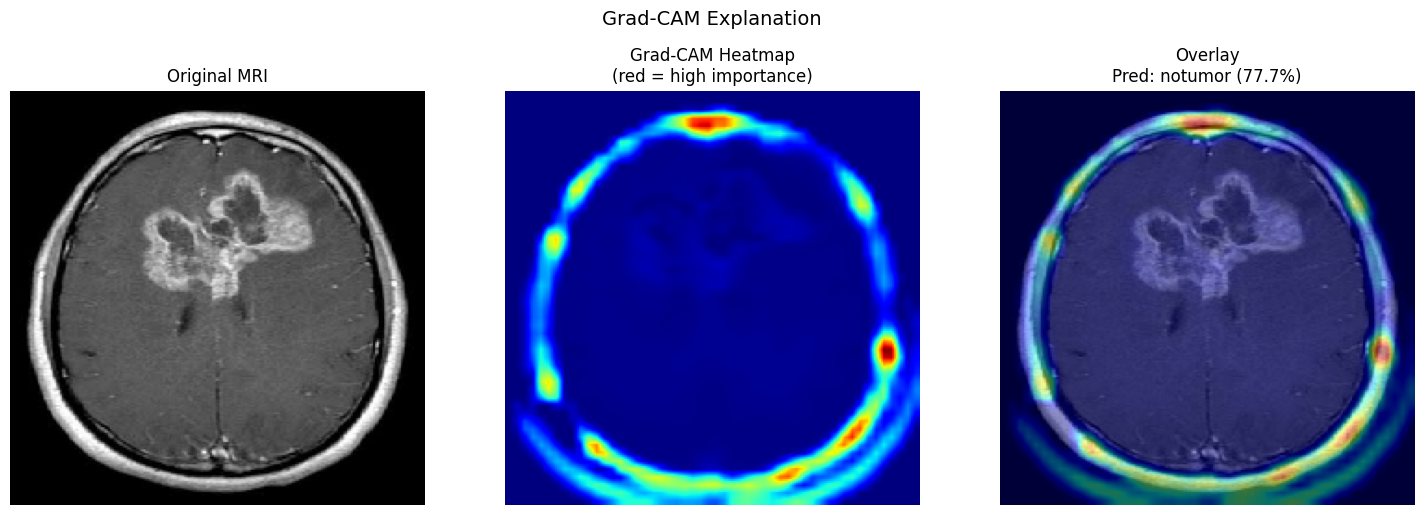

Hot-region coverage (threshold=0.5): 3.1% of image
Smaller focused region = more confident, trustworthy prediction.


In [27]:
import tensorflow as tf
import cv2

def get_gradcam_heatmap(model, image, layer_name="last_conv"):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(image)
        class_idx = tf.argmax(preds[0])
        loss = preds[:, class_idx]
    grads = tape.gradient(loss, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_out[0] @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / (np.max(heatmap) + 1e-8)
    return heatmap

heatmap = get_gradcam_heatmap(model, input_img)
heatmap_resized = cv2.resize(heatmap, (224, 224))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title("Original MRI")
axes[1].imshow(heatmap_resized, cmap="jet"); axes[1].axis("off")
axes[1].set_title("Grad-CAM Heatmap\n(red = high importance)")
axes[2].imshow(img); axes[2].imshow(heatmap_resized, cmap="jet", alpha=0.45)
axes[2].axis("off")
axes[2].set_title(f"Overlay\nPred: {CATEGORIES[pred_lbl]} ({confidence:.1f}%)")
plt.suptitle("Grad-CAM Explanation", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

hot_threshold = 0.5
hot_fraction = np.mean(heatmap_resized >= hot_threshold) * 100
print(f"Hot-region coverage (threshold={hot_threshold}): {hot_fraction:.1f}% of image")
print("Smaller focused region = more confident, trustworthy prediction.")


### Attention Map — Built-in Spatial Gate
Bright = attention mechanism amplified this location. Dark = suppressed.
> **Trust check:** Compare with Grad-CAM. If both agree, the model is consistent.


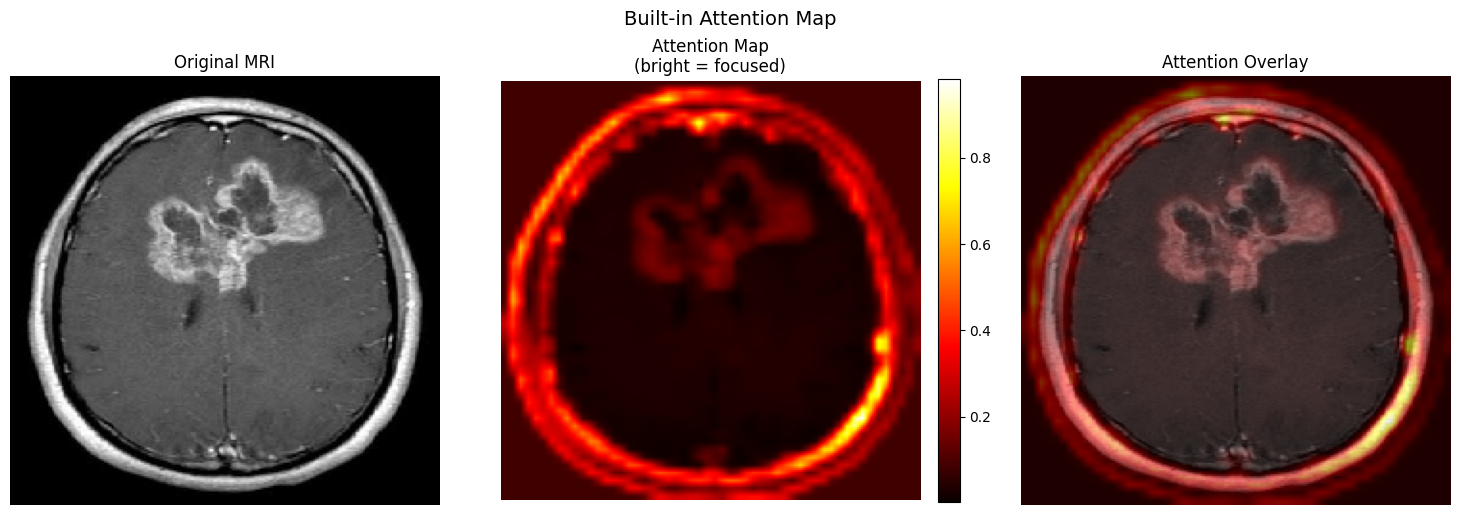

Attention entropy: 7.4965  (lower = more focused = more trustworthy)


In [28]:
# Layer index 4 = Multiply (attention output) in this architecture
attention_model = tf.keras.Model(inputs=model.input,
                                  outputs=model.get_layer(index=4).output)
attn_map = attention_model.predict(input_img, verbose=0)[0]
attn_mean = np.mean(attn_map, axis=-1)
attn_norm = (attn_mean - attn_mean.min()) / (attn_mean.max() - attn_mean.min() + 1e-8)
attn_large = cv2.resize(attn_norm, (224, 224))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title("Original MRI")
im = axes[1].imshow(attn_large, cmap="hot")
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].axis("off"); axes[1].set_title("Attention Map\n(bright = focused)")
axes[2].imshow(img); axes[2].imshow(attn_large, cmap="hot", alpha=0.5)
axes[2].axis("off"); axes[2].set_title("Attention Overlay")
plt.suptitle("Built-in Attention Map", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

from scipy.stats import entropy
flat = attn_norm.flatten() + 1e-10
flat = flat / flat.sum()
attn_ent = entropy(flat)
print(f"Attention entropy: {attn_ent:.4f}  (lower = more focused = more trustworthy)")


### LIME — Superpixel-level Explanation
Green boundary = superpixel that **supports** the prediction. Red = **opposes** it.
> **Trust check:** Green segments should cover the tumour region, not background.
> If LIME, Grad-CAM, and Attention all highlight the same area, trust is HIGH.


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


  1%|          | 10/1000 [00:00<00:13, 75.07it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


  2%|▏         | 20/1000 [00:00<00:13, 75.38it/s]

...

 98%|█████████▊| 980/1000 [00:14<00:00, 70.25it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


 99%|█████████▉| 990/1000 [00:14<00:00, 71.61it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


100%|██████████| 1000/1000 [00:14<00:00, 69.49it/s]


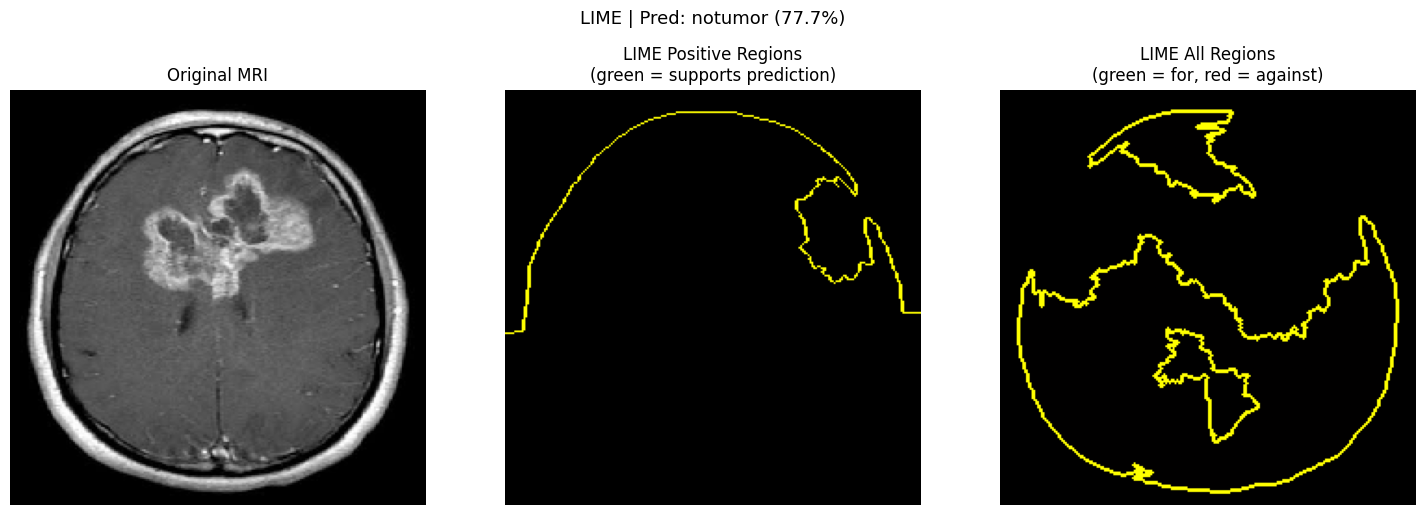

Top-5 superpixel weights:
  Segment  18: -0.0323  AGAINST
  Segment  19: -0.0205  AGAINST
  Segment  15: -0.0196  AGAINST
  Segment   5: -0.0148  AGAINST
  Segment  16: -0.0095  AGAINST


In [29]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    img.astype("double"), model.predict,
    top_labels=1, hide_color=0, num_samples=1000
)
top_label = explanation.top_labels[0]

temp_pos, mask_pos = explanation.get_image_and_mask(
    top_label, positive_only=True, num_features=5, hide_rest=False)
temp_both, mask_both = explanation.get_image_and_mask(
    top_label, positive_only=False, num_features=5, hide_rest=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title("Original MRI")
axes[1].imshow(mark_boundaries(temp_pos / 255.0, mask_pos))
axes[1].axis("off"); axes[1].set_title("LIME Positive Regions\n(green = supports prediction)")
axes[2].imshow(mark_boundaries(temp_both / 255.0, mask_both))
axes[2].axis("off"); axes[2].set_title("LIME All Regions\n(green = for, red = against)")
plt.suptitle(f"LIME | Pred: {CATEGORIES[top_label]} ({confidence:.1f}%)", fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

local_exp = explanation.local_exp[top_label]
print("Top-5 superpixel weights:")
for seg_id, w in sorted(local_exp, key=lambda x: abs(x[1]), reverse=True)[:5]:
    direction = "FOR" if w > 0 else "AGAINST"
    print(f"  Segment {seg_id:3d}: {w:+.4f}  {direction}")


### Cross-Method Trustworthiness Panel
Side-by-side comparison of all three explanation methods on the same image. **Consistent highlighting = high trust.** Conflicting highlights = investigate further.


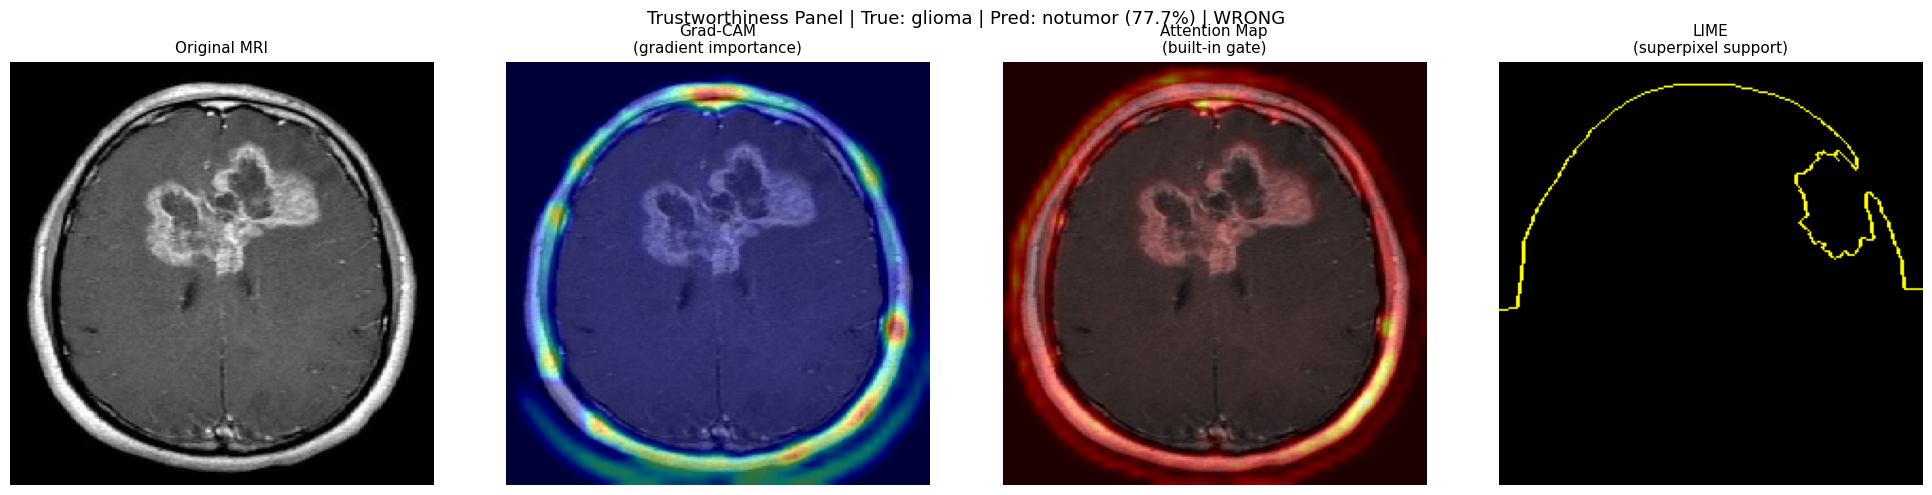


TRUSTWORTHINESS SUMMARY
  Predicted class   : notumor
  True class        : glioma
  Model confidence  : 77.74%
  Attention entropy : 7.4965  (lower = more focused)
  Grad-CAM hotspot  : 3.1% of image area

  >> Overall trust signal: MODERATE


In [30]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title("Original MRI", fontsize=11)

axes[1].imshow(img)
axes[1].imshow(heatmap_resized, cmap="jet", alpha=0.45)
axes[1].axis("off"); axes[1].set_title("Grad-CAM\n(gradient importance)", fontsize=11)

axes[2].imshow(img)
axes[2].imshow(attn_large, cmap="hot", alpha=0.5)
axes[2].axis("off"); axes[2].set_title("Attention Map\n(built-in gate)", fontsize=11)

axes[3].imshow(mark_boundaries(temp_pos / 255.0, mask_pos))
axes[3].axis("off"); axes[3].set_title("LIME\n(superpixel support)", fontsize=11)

outcome_str = "CORRECT" if pred_lbl == true_lbl else "WRONG"
fig.suptitle(
    f"Trustworthiness Panel | True: {CATEGORIES[true_lbl]} | "
    f"Pred: {CATEGORIES[pred_lbl]} ({confidence:.1f}%) | {outcome_str}",
    fontsize=13
)
plt.tight_layout(); plt.show()

print()
print("=" * 60)
print("TRUSTWORTHINESS SUMMARY")
print("=" * 60)
print(f"  Predicted class   : {CATEGORIES[pred_lbl]}")
print(f"  True class        : {CATEGORIES[true_lbl]}")
print(f"  Model confidence  : {confidence:.2f}%")
print(f"  Attention entropy : {attn_ent:.4f}  (lower = more focused)")
print(f"  Grad-CAM hotspot  : {hot_fraction:.1f}% of image area")
print()
trust = "HIGH" if confidence > 70 and hot_fraction < 30 and attn_ent < 5 else "MODERATE"
print(f"  >> Overall trust signal: {trust}")
print("=" * 60)
